In [2]:
import pandas as pd
from pathlib import Path
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
PROJECT_ROOT = Path.cwd().parent
data_path = PROJECT_ROOT / "data"

database_path = next(data_path.rglob("ptbxl_database.csv"))
statements_path = next(data_path.rglob("scp_statements.csv"))

df = pd.read_csv(database_path)
scp = pd.read_csv(statements_path, index_col=0)

In [4]:
print('Размер основной базы ЭКГ: ', df.shape)
# 21799 записей, 28 признаков
print("Размер справочника кодов:", scp.shape)
# справочник содержит 71 код

Размер основной базы ЭКГ:  (21799, 28)
Размер справочника кодов: (71, 12)


In [5]:
print('Столбцы датасета ЭКГ (ptbxl_database.csv):', df.columns)

Столбцы датасета ЭКГ (ptbxl_database.csv): Index(['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse',
       'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr'],
      dtype='str')


## Работа с пропусками

In [6]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing_values, "missing_percent": missing_percent})
missing_table = missing_table.sort_values(by="missing_percent", ascending=False)
print(missing_table)

                              missing_count  missing_percent
electrodes_problems                   21769            99.86
infarction_stadium2                   21696            99.53
pacemaker                             21508            98.67
burst_noise                           21186            97.19
baseline_drift                        20201            92.67
extra_beats                           19850            91.06
static_noise                          18539            85.05
infarction_stadium1                   16187            74.26
height                                14825            68.01
weight                                12378            56.78
validated_by                           9378            43.02
heart_axis                             8468            38.85
nurse                                  1473             6.76
site                                     17             0.08
strat_fold                                0             0.00
validated_by_human      

* Больше 90% пропусков в столбах: electrodes_problems, pacemaker, burst_noise, baseline_drift, extra_beats
* Больше 70%: static_noise, infarction_stadium1
* Больше 50%: height, weight

Тем не менее, все названные признаки относятся к дополнительным полям, не несущим ключевой информации (Additional fields are heart_axis, infarction_stadium1, infarction_stadium2, validated_by, second_opinion, initial_autogenerated_report and validated_by_human.)
Но все же с ними придется работать. Либо стоит заполнять, где пропусков не так много, либо вообще удалять признаки.  **Необходимость использования дополнительных метаданных будет оцениваться отдельно, на этапе обучения модели**.

**Авторы считают scp_codes и report - ключевыми признаками**, и они, к счастью, полностью заполнены. *Пропусков так же нет в возрасте и поле*, а они относятся к важным признакам

## Работа с дублями

In [7]:
print("Полностью дублирующиеся строки:", df.duplicated().sum())
print("Дублирующиеся patient_id:", df["patient_id"].duplicated().sum())
print('\nCколько уникальных пациентов:', df["patient_id"].nunique(), f"из {df.shape[0]}")
print("Записей на одного пациента в среднем:", len(df) / df["patient_id"].nunique())

Полностью дублирующиеся строки: 0
Дублирующиеся patient_id: 2930

Cколько уникальных пациентов: 18869 из 21799
Записей на одного пациента в среднем: 1.1552811489745085


* В данных нет случайно продублированных записей
* Но некоторые пациенты встречаются в датасете по несколько раз, а поэтому нельзя автоматически считать каждую запись независимым пациентом

## Работа с ключевыми признаками

### ВОЗРАСТ

In [8]:
print(df['age'].describe()) # есть возраст 300 лет.
print('Сколько записей с людьми старше 100 лет:', df[df['age'] > 100].shape[0])
print('Распределение по возрасту старше 100 лет\n', df[df['age'] > 100]['age'].value_counts(dropna=False))

count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64
Сколько записей с людьми старше 100 лет: 293
Распределение по возрасту старше 100 лет
 age
300.0    293
Name: count, dtype: int64


293 записи - клиентам 300 лет

В описании датасета написано, что возраст пациентов старше 89 лет представлен значениями из диапазона около 300 лет, чтобы соблюсти требования HIPAA по защите медицинских данных. То есть, **300 лет - не ошибка, а сократие реального возхраста пожилым клиентов**. Тем не менее, если мы потом будем анализировать зависимость возраста от диагностических классов, **значение 300 нельзя включать как настоящий возраст. Его нужно отдельно обозначать как неизвестный/обезличенный возраст**.
-> создаем столбец, где заменяем 300 на обезличенный возраст, чтобы при обучении использовать только правдивые данные

In [9]:
df["age_clean"] = df["age"].replace(300, np.nan) 

### ПОЛ

In [10]:
print(df['sex'].value_counts(dropna=False, normalize=True)) # примерно в равном отношении пол

sex
0    0.52085
1    0.47915
Name: proportion, dtype: float64


### Распределение ФОЛДОВ (как устроено разделение данных?)

In [11]:
print(df["strat_fold"].value_counts().sort_index())

strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64


Авторы рекомендуют: Records in fold 9 and 10 underwent at least one human evaluation and are therefore of a particularly high label quality. **We therefore propose to use folds 1-8 as training set, fold 9 as validation set and fold 10 as test set**.
-> фолды распределены примерно в равном отношении

### РОСТ И ВЕС

In [12]:
print(df[['height', 'weight']].describe()) # все в пределах челоческих размеров

            height       weight
count  6974.000000  9421.000000
mean    166.702323    70.995223
std      10.867321    15.878803
min       6.000000     5.000000
25%     160.000000    60.000000
50%     166.000000    70.000000
75%     174.000000    80.000000
max     209.000000   250.000000


## СПРАВОЧНИК ДИАГНОСТИЧЕСКИХ КОДОВ

Авторы датасета говорят, что: For diagnostic statements, we also provide a proposed hierarchical organization into diagnostic_class and diagnostic_subclass.
* diagnostic_subclass — конкретная метка, присвоенная записи ЭКГ.
* diagnostic_class — более крупная категория, объединяющая несколько диагностических кодов.
* description — описание диагностического кода
* diagnostic — относится ли код к диагностическим -> Учитываем ли мы этот код как диагностическую метку в нашей задаче?

In [13]:
print('Столбцы датасета с аннотациями (scp_statements.csv):', scp.columns)

Столбцы датасета с аннотациями (scp_statements.csv): Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='str')


In [14]:
print(scp["diagnostic"].value_counts(dropna=False)) # то есть, диагностировать будем 44 кода.
print('\n', scp["diagnostic_class"].value_counts(dropna=False)) # Для построения таргета используем только диагностические коды с заполненным diagnostic_class.
print('\n', scp["diagnostic_subclass"].value_counts(dropna=False))

diagnostic
1.0    44
NaN    27
Name: count, dtype: int64

 diagnostic_class
NaN     27
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64

 diagnostic_subclass
NaN          27
IMI           6
AMI           6
STTC          5
ISCA          4
_AVB          3
LAFB/LPFB     2
ISCI          2
NST_          1
NORM          1
LVH           1
ISC_          1
IRBBB         1
IVCD          1
CRBBB         1
CLBBB         1
LAO/LAE       1
LMI           1
RVH           1
RAO/RAE       1
WPW           1
ILBBB         1
SEHYP         1
PMI           1
Name: count, dtype: int64


## ТАРГЕТ

Необходимо отдельно поработать с целевой переменной, потому что на данный момент формат записи неудобен для обучения модели. 
-> **Мы преобразуем исходные scp_codes в пять укрупнённых классов (NORM, MI, STTC, CD, HYP -- ориентируясь на классы датасета scp), чтобы объединить отдельные диагностические коды в более общие категории и сформировать целевые метки для задачи многоклассовой классификации.**

In [15]:
df["scp_dict"] = df["scp_codes"].apply(ast.literal_eval) # из строки в словарь

scp_final = scp[(scp["diagnostic"] == 1) & (scp["diagnostic_class"].notna())]
def get_superclass(scp_codes):
    classes = set()
    for scp_code in scp_codes.keys():
        if scp_code in scp_final.index:
            classes.add(scp_final.loc[scp_code, "diagnostic_class"])

    return sorted(classes)

df['scp_class'] = df['scp_dict'].apply(get_superclass)

all_classes = list(scp_final['diagnostic_class'].unique())
for class_name in all_classes:
    df[class_name] = df['scp_class'].apply(lambda x: int(class_name in x))

print('Распределение классов:')
for class_name in all_classes:
    print(f'{class_name}: {round(df[class_name].sum() / df.shape[0], 2) * 100}%')

Распределение классов:
STTC: 24.0%
NORM: 44.0%
MI: 25.0%
HYP: 12.0%
CD: 22.0%


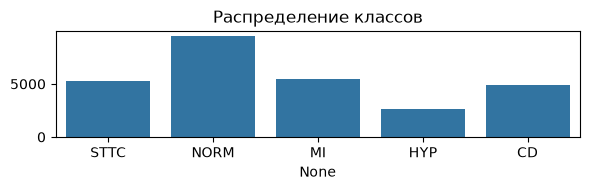

In [26]:
classes_df = df[all_classes].copy()
cls = classes_df.sum()
plt.figure(figsize=(6, 2))
sns.barplot(x=cls.index, y=cls.values)
plt.title("Распределение классов")
plt.tight_layout()
plt.show();

Есть некий **дисбаланс классов**: HYP встревчается реже всего - 12%, NORM больше всего - 44%. Стоит внимательно проверять при обучении не будет ли модель искусственно ставить NORM, чтобы повысить качество..
**В дальнейшем нужно будет внимательно оценивать качество по каждому классу, а не только общую точность**

In [33]:
labels_counting = classes_df.sum(axis=1).value_counts()

print(f'Долевое соотношение количества меток на 1 запись ЭКГ:\n{labels_counting / classes_df.shape[0]}')

Долевое соотношение количества меток на 1 запись ЭКГ:
1    0.745172
2    0.186614
3    0.042158
0    0.018854
4    0.007202
Name: count, dtype: float64


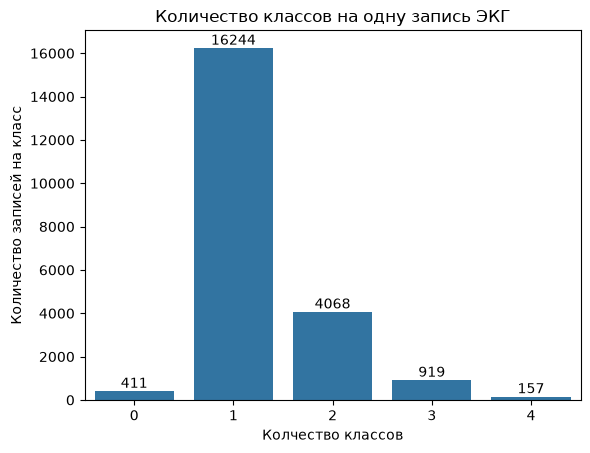

In [34]:
fig, ax = plt.subplots()
sns.barplot(x=labels_counting.index, y=labels_counting.values, ax=ax)
plt.title("Количество классов на одну запись ЭКГ")
plt.xlabel("Колчество классов")
plt.ylabel("Количество записей на класс")
ax.bar_label(ax.containers[0])
plt.show()

В основном на одну ЭКГ приходится - 1 класс (в 75% случаев), 2 класса - в 19%. 3, 0, 4 класса - в сумме реже, чем 7%.

In [36]:
zero_label_records = (classes_df.sum(axis=1) == 0)
print("Доля записей без выбранных диагностических меток:", round(zero_label_records.mean() * 100, 2), "%")
zero_df = df[df[all_classes].sum(axis=1) == 0]

def fold_to_split(fold):
    if fold <= 8:
        return "train"
    elif fold == 9:
        return "val"
    else:
        return "test"

print('\nВ какие фолды попали такие случаи без меток:\n', zero_df['strat_fold'].map(fold_to_split).value_counts())

Доля записей без выбранных диагностических меток: 1.89 %

В какие фолды попали такие случаи без меток:
 strat_fold
train    334
test      40
val       37
Name: count, dtype: int64


Есть записи вообще без выбранных диагностических меток, и большая часть попала как раз в train. Возможно, **есть смысл вообще исключить такие записи из train**

# Итоговые выводы

## Структура и качество данных

* Датасет PTB-XL содержит 21 799 записей ЭКГ и 28 признаков. 
* Справочник scp_statements.csv включает 71 диагностический и недиагностический код, из которых 44 помечены как диагностические.

**Пропущенные значения**: значительная доля пропусков обнаружена в дополнительных  **метаданных**. При этом пропуски отсутствуют в scp_codes, age и sex. Необходимость использования дополнительных метаданных и способы обработки пропусков будут определяться отдельно при подготовке данных к обучению.

**Дубликаты и структура пациентов**: полностью дублирующихся строк в датасете не обнаружено. При этом количество уникальных записей не совпадает с уникальным числом клиентов, то есть некоторые пациенты имеют несколько записей ЭКГ. Это **необходимо учитывать при разделении данных на обучающую, валидационную и тестовую выборки, чтобы записи одного пациента не попадали одновременно в разные выборки**.

 **Возраст пациентов**: в 293 записях обнаружено значение **возраста 300 лет**. Согласно описанию от авторов, такие значения используются для обезличивания возраста пациентов старше 89 лет и не являются реальным возрастом. Поэтому при анализе возрастных зависимостей их следует рассматривать как неизвестные значения, а не как фактический возраст.

**Пол**: распределение записей относительно сбалансировано

**Разбиение данных**: записи распределены между десятью фолдами примерно равномерно. Согласно рекомендациям авторов датасета, фолды 1-8 предлагается использовать для обучения, фолд 9 - для валидации, фолд 10 - для тестирования. 

## Таргет

Из исходных диагностических кодов scp_codes были выделены **пять диагностических классов**: NORM, MI, STTC, CD и HYP.

Присутствует **дисбаланс классов**: HYP встречается реже остальных категорий, тогда как NORM представлен наиболее широко. При обучении модели важно оценивать качество предсказаний отдельно для каждого класса, а не ориентироваться исключительно на общую метрику качества.

**Анализ количества целевых меток на одну запись** ЭКГ показал, что:
* 74,52% записей имеют одну диагностическую метку;
* 18,66% - две метки;
* 4,22% - три метки;
* 0,72% - четыре метки;
* 1,89% не имеют ни одной из пяти выбранных меток.

Это подтверждает **необходимость задачи многоклассовой классификации**.

Отдельного внимания требуют **1,89% записей, для которых не удалось определить ни один из пяти выбранных классов**. До обучения модели необходимо дополнительно принять решение об их обработке.

## Что дальше?
*  Определить необходимость использовать *метаданные* при обучении модели. В случае использования — корректно обработать пропуски
* Продумать *корректное разделение данных на train, val, test*. Тут можно следовать рекомендациям авторов, но коллективное обсуждение необходимо. 
* Необходимо *зафиксировать единый алгоритм преобразования scp_codes в пять диагностических классов* для последующего обучения модели, так как текущий формат записи в дотаяете неудобен 
*  Продумать *алгоритм работы с записями без выбранных меток*. Стоит обсудить, следует ли исключать их из обучения или обрабатывать отдельно.
* Использовать *правильные метрики качества модели*, чтобы минимизировать проблему дисбаланса классов
